# k-nearest neighbors

Companion notebook for the *k-nearest neighbors* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn class that does the same job.

**Data:** the Iris flowers (150 flowers, 4 measurements, 3 species) and, for regression,
the Diabetes data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_diabetes, load_iris
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
K = 5
K_CHOICES = range(1, 40, 2)

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

## 1. Distance between examples

$d(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_j (a_j - b_j)^2}$, for every test flower against every training flower.

In [2]:
distances_by_hand = np.sqrt(((X_test[:, None, :] - X_train[None, :, :]) ** 2).sum(axis=2))
print("distance table:", distances_by_hand.shape)
print("same result:", np.allclose(distances_by_hand, euclidean_distances(X_test, X_train)))

distance table: (45, 105)
same result: True


## 2. Vote of the k nearest

Take the $k$ closest training flowers and predict the species that appears most often among them.

In [3]:
nearest = np.argsort(distances_by_hand, axis=1)[:, :K]
predictions_by_hand = np.array([np.bincount(y_train[rows]).argmax() for rows in nearest])

In [4]:
classifier = KNeighborsClassifier(n_neighbors=K).fit(X_train, y_train)
print("same predictions:", np.array_equal(predictions_by_hand, classifier.predict(X_test)))
print(f"test accuracy {classifier.score(X_test, y_test):.3f}")

same predictions: True
test accuracy 0.978


## 3. Average of the k nearest

For a number, the prediction is the mean of the neighbors' values: $\hat{y} = \frac{1}{k}\sum_{i \in N_k(\mathbf{x})} y_i$.

In [5]:
X_d, y_d = load_diabetes(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_d, y_d, test_size=0.3, random_state=RANDOM_STATE)

nearest = np.argsort(euclidean_distances(Xd_test, Xd_train), axis=1)[:, :K]
averages_by_hand = yd_train[nearest].mean(axis=1)

In [6]:
regressor = KNeighborsRegressor(n_neighbors=K).fit(Xd_train, yd_train)
print("same predictions:", np.allclose(averages_by_hand, regressor.predict(Xd_test)))

same predictions: True


## 4. Choosing k

Small $k$ follows every point, large $k$ smooths too much. Cross-validation picks a value in between.
The features are scaled first because k-NN works with distances.

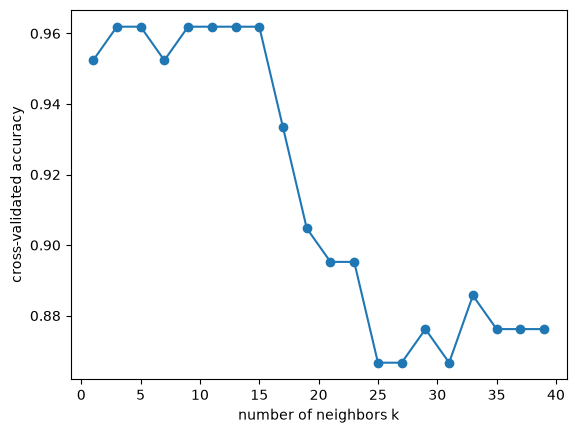

In [7]:
cv_accuracy = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                               X_train, y_train, cv=5).mean()
               for k in K_CHOICES]

plt.plot(K_CHOICES, cv_accuracy, marker="o")
plt.xlabel("number of neighbors k")
plt.ylabel("cross-validated accuracy")
plt.show()

## Exercises

1. Use the Manhattan distance $\sum_j |a_j - b_j|$ in section 1 and compare with `KNeighborsClassifier(metric="manhattan")`.
2. Write a weighted vote with weights $1/d$ and compare with `KNeighborsClassifier(weights="distance")`.
3. Find the best $k$ from section 4 and report its test accuracy once.